# 06 – Indicadores no semestre anterior à primeira saída

Issue #9. Responde P4: *CRE, frequência e reprovações no semestre anterior à primeira saída diferem dos de alunos sem saída?*

Usa a visão aluno-semestre e as definições da issue #6 (`src/eventos.py`), já sem o código de aluno especial, e as decisões de tratamento da issue #5. As funções desta análise estão em `src/comparacao.py`.

> Só números agregados. Grupos com menos de 10 alunos aparecem como `<10` (`src/privacidade.py`). Nenhum `HANDLE*` aparece nas saídas, e os gráficos não mostram pontos individuais.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.dados import carregar_base
from src.eventos import consolidar_aluno_semestre, filtrar_graduacao, marcar_evento_saida, marcar_saida_semestre_seguinte
from src.comparacao import (
    INDICADORES, estatisticas_boxplot, montar_grupos, preparar_indicadores, proporcao_ao_menos_um,
    resumo_ponderado, semestre_anterior_a_saida,
)
from src.privacidade import LIMITE_MINIMO, ocultar_contagens_pequenas

FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

def br(valor, casas=1):
    """Número no formato brasileiro (vírgula decimal, ponto de milhar)."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")

base = carregar_base()
aluno_semestre = preparar_indicadores(
    marcar_saida_semestre_seguinte(consolidar_aluno_semestre(marcar_evento_saida(filtrar_graduacao(base))))
)
print("Visão aluno-semestre pronta.")

Visão aluno-semestre pronta.


## 1. Regras da comparação

**Semestre anterior à saída.** Para cada aluno com evento de saída, o último semestre **estritamente anterior** à primeira saída em que ele cursou o semestre (linha `ACADEMICA`). Usa-se o semestre anterior porque, no semestre da própria saída, quase não há dado acadêmico: a maior parte das saídas está em linhas `OCORRENCIA`. Em geral é o semestre imediatamente anterior, mas pode ser um pouco antes (por exemplo, quando há um trancamento no meio); a seção 3 mostra quantos casos são.

**Grupo de comparação.** Semestres `ACADEMICA`, **no mesmo semestre e curso**, de alunos que ainda não tinham tido evento de saída naquele momento. Entram também os semestres de quem só vai sair mais tarde; não entram os semestres da primeira saída em diante nem os próprios semestres anteriores à saída.

**Pesos.** Cada célula semestre × curso pesa no grupo de comparação o mesmo que pesa no grupo com saída. Assim, a comparação não muda conforme o número de colegas de cada célula, e diferenças entre cursos ou épocas não se misturam com a diferença entre os grupos. Células sem os dois grupos ficam de fora.

**Versão simplificada.** Diferente do TCC, não há ponderação por período curricular: um aluno do 1º período pode ser comparado com colegas de períodos mais avançados do mesmo curso e semestre. Essa escolha foi feita para manter a análise simples e entra como limitação.

**Tratamento dos dados (issue #5).** Frequência acima de 100% é inválida e vira ausente. Os demais vazios continuam vazios (não viram zero): cada indicador usa só quem tem o valor preenchido, e os ausentes são contados na tabela da seção 4.

## 2. Quem entra na comparação

In [2]:
anterior = semestre_anterior_a_saida(aluno_semestre)
saida, comparacao = montar_grupos(aluno_semestre)

com_saida = aluno_semestre.loc[aluno_semestre["PRIMEIRA_SAIDA_ORD"].notna()]
alunos_com_saida = com_saida["HANDLEALUNO"].nunique()
primeiro_semestre = aluno_semestre.groupby("HANDLEALUNO")["ANOSEMESTRE_ORD"].min()
primeira = com_saida.drop_duplicates("HANDLEALUNO").set_index("HANDLEALUNO")["PRIMEIRA_SAIDA_ORD"]
fora = primeira.loc[~primeira.index.isin(saida["HANDLEALUNO"])]
fora_primeiro_semestre = int((fora == primeiro_semestre.reindex(fora.index)).sum())

entrada = pd.Series({
    "Alunos com evento de saída": alunos_com_saida,
    "Fora: primeira saída no primeiro semestre em que aparecem na base": fora_primeiro_semestre,
    "Fora: outros motivos (sem semestre cursado antes da saída ou sem colegas no mesmo semestre e curso)": len(fora) - fora_primeiro_semestre,
    "Alunos com saída incluídos na comparação": len(saida),
}, name="alunos")
assert entrada.iloc[1:].min() >= LIMITE_MINIMO
assert entrada.iloc[0] == entrada.iloc[1] + entrada.iloc[2] + entrada.iloc[3]
display(ocultar_contagens_pequenas(entrada).to_frame())

grupo_comp = pd.Series({
    "Semestres de comparação": len(comparacao),
    "Alunos distintos na comparação": comparacao["HANDLEALUNO"].nunique(),
    "   dos quais têm evento de saída mais tarde": comparacao.loc[comparacao["PRIMEIRA_SAIDA_ORD"].notna(), "HANDLEALUNO"].nunique(),
    "Células semestre × curso comparadas": saida.groupby(["ANOSEMESTRE_ORD", "SIGLACURSO"]).ngroups,
}, name="quantidade")
display(ocultar_contagens_pequenas(grupo_comp).to_frame())
print(f"Semestres anteriores à saída: de {saida['ANOSEMESTRE'].min()} a {saida['ANOSEMESTRE'].max()}.")

,alunos
Alunos com evento de saída,3.425
Fora: primeira saída no primeiro semestre em que aparecem na base,1.560
Fora: outros motivos (sem semestre cursado antes da saída ou sem colegas no mesmo semestre e curso),15
Alunos com saída incluídos na comparação,1.850


,quantidade
Semestres de comparação,37.417
Alunos distintos na comparação,5.099
dos quais têm evento de saída mais tarde,1.257
Células semestre × curso comparadas,222


Semestres anteriores à saída: de 2009/2 a 2025/2.


Quase metade dos alunos com saída fica de fora porque a primeira saída acontece já no primeiro semestre em que aparecem na base: não existe um semestre anterior para descrever (o mesmo ponto registrado na issue #6). O resultado abaixo vale, portanto, para quem **cursou pelo menos um semestre antes de sair**.

## 3. Distância entre o semestre anterior e a primeira saída

In [3]:
distancia = (
    saida["SEMESTRES_ATE_SAIDA"].clip(upper=3)
    .map({1: "1 (imediatamente anterior)", 2: "2", 3: "3 ou mais"})
    .value_counts().reindex(["1 (imediatamente anterior)", "2", "3 ou mais"])
)
assert distancia.min() >= LIMITE_MINIMO
tabela_distancia = pd.DataFrame({
    "alunos": ocultar_contagens_pequenas(distancia),
    "%": (distancia / distancia.sum() * 100).map(br),
}).rename_axis("semestres até a primeira saída")
tabela_distancia

,alunos,%
semestres até a primeira saída,,
1 (imediatamente anterior),1.451,"78,4"
2,323,"17,5"
3 ou mais,76,"4,1"


## 4. Comparação dos indicadores

- **Média e mediana da comparação** são ponderadas pela composição semestre × curso do grupo com saída.
- **Prob. superioridade**: chance de um aluno com saída ter valor **maior** que um colega do mesmo semestre e curso (estatística U de Mann-Whitney dividida por n1 × n2, calculada em cada célula e combinada). **0,50 = sem diferença**; perto de 0 = o grupo com saída tem valores menores; perto de 1 = maiores. Usamos essa medida, como apoio exploratório, em vez de p-valor: com milhares de semestres, quase qualquer diferença daria "significativa", e o que interessa é o tamanho da diferença.

In [4]:
resumo = resumo_ponderado(saida, comparacao)
assert (resumo["n saída (alunos)"] + resumo["ausentes saída"] == len(saida)).all()
assert resumo[["n saída (alunos)", "n comparação (semestres)"]].min().min() >= LIMITE_MINIMO
assert ((resumo["ausentes saída"] == 0) | (resumo["ausentes saída"] >= LIMITE_MINIMO)).all()

exibir = resumo.copy()
for coluna in ["n saída (alunos)", "ausentes saída", "n comparação (semestres)"]:
    exibir[coluna] = ocultar_contagens_pequenas(exibir[coluna])
for coluna in ["média saída", "média comparação", "mediana saída", "mediana comparação"]:
    exibir[coluna] = exibir[coluna].map(br)
exibir["prob. superioridade"] = exibir["prob. superioridade"].map(lambda v: br(v, 2))
exibir

,n saída (alunos),ausentes saída,n comparação (semestres),média saída,média comparação,mediana saída,mediana comparação,prob. superioridade
Indicador,,,,,,,,
CRE do semestre,1.593,257,37.032,"24,9","59,1","21,3","63,0","0,14"
CRE acumulado,1.676,174,37.103,"32,3","58,8","31,7","60,8","0,16"
Frequência (%),1.580,270,36.867,"79,9","91,7","85,0","93,9","0,24"
Disciplinas com mais de 25% de faltas,1.580,270,36.869,"1,1","0,2","0,0","0,0","0,67"
Reprovações no semestre,1.850,0,37.417,"2,7","1,1","3,0","0,0","0,74"
Retiradas no semestre,1.850,0,37.417,"0,5","0,3","0,0","0,0","0,54"


Nas três contagens (faltas, reprovações e retiradas) a maioria dos semestres tem zero, então a mediana não mostra a diferença. Para elas, a medida mais clara é o **percentual de semestres com pelo menos 1**.

In [5]:
CONTAGENS = ["IA04_02", "IA34_03", "IA65_03"]
ao_menos_um = pd.DataFrame(
    [proporcao_ao_menos_um(saida, comparacao, c) for c in CONTAGENS],
    index=[INDICADORES[c] for c in CONTAGENS], columns=["% antes da saída", "% colegas sem saída"],
)
ao_menos_um.rename_axis("semestres com pelo menos 1").map(br)

,% antes da saída,% colegas sem saída
semestres com pelo menos 1,,
Disciplinas com mais de 25% de faltas,"43,4","10,4"
Reprovações no semestre,"77,9","47,4"
Retiradas no semestre,"24,0","17,0"


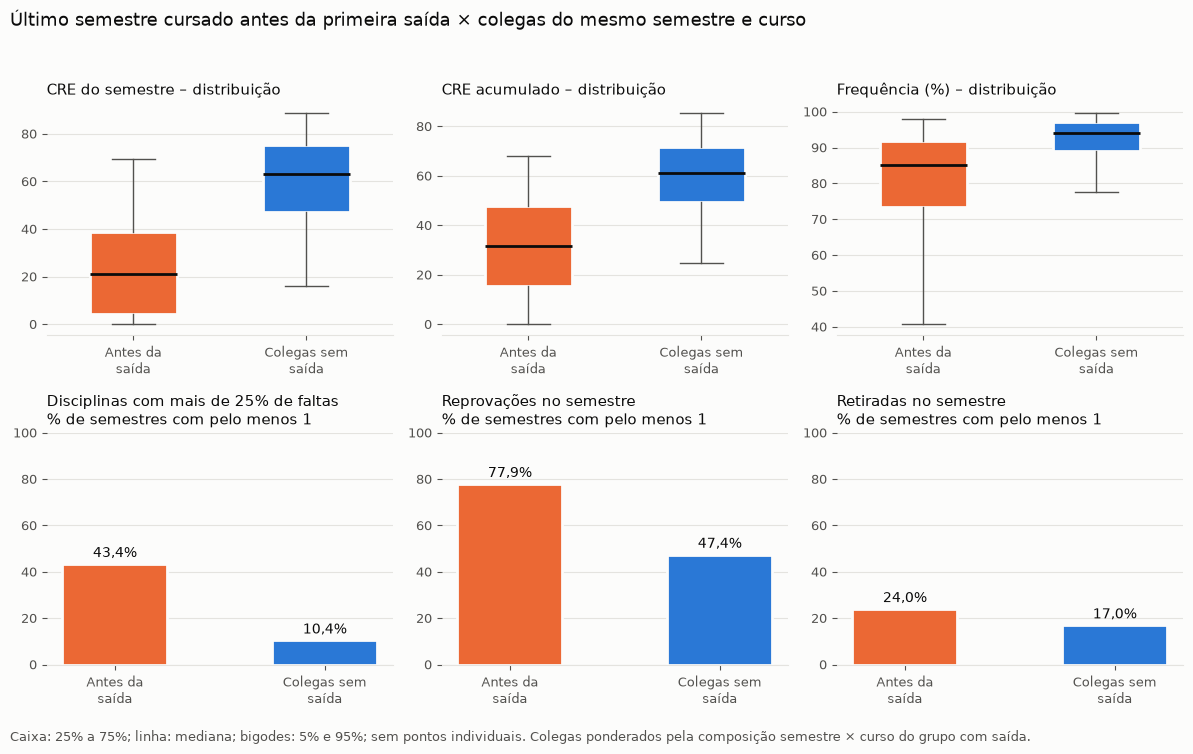

In [6]:
LARANJA, AZUL = "#eb6834", "#2a78d6"
TEXTO, TEXTO_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

ROTULOS = ["Antes da\nsaída", "Colegas sem\nsaída"]
CONTINUAS = ["CRENOSEMESTRE", "CREATESEMESTRE", "IA04_01"]

fig, eixos = plt.subplots(2, 3, figsize=(12, 7.5), facecolor=FUNDO)
for ax, coluna in zip(eixos[0], CONTINUAS):
    c = comparacao.loc[comparacao[coluna].notna()]
    stats = [
        estatisticas_boxplot(saida[coluna].dropna(), label=ROTULOS[0]),
        estatisticas_boxplot(c[coluna], c["GRUPO_PESO"], label=ROTULOS[1]),
    ]
    caixas = ax.bxp(stats, showfliers=False, patch_artist=True, widths=0.5,
                    medianprops={"color": TEXTO, "linewidth": 2},
                    whiskerprops={"color": TEXTO_2}, capprops={"color": TEXTO_2})
    for caixa, cor in zip(caixas["boxes"], [LARANJA, AZUL]):
        caixa.set(facecolor=cor, edgecolor=FUNDO, linewidth=2)
    ax.set_title(INDICADORES[coluna] + " – distribuição", color=TEXTO, fontsize=11, loc="left")
for ax, coluna in zip(eixos[1], CONTAGENS):
    valores = ao_menos_um.loc[INDICADORES[coluna]].to_numpy()
    barras = ax.bar([0, 1], valores, width=0.5, color=[LARANJA, AZUL], edgecolor=FUNDO, linewidth=2)
    for barra, valor in zip(barras, valores):
        ax.text(barra.get_x() + barra.get_width() / 2, valor + 1.5, br(valor) + "%",
                ha="center", va="bottom", color=TEXTO, fontsize=10)
    ax.set_xticks([0, 1], ROTULOS)
    ax.set_ylim(0, 100)
    ax.set_title(INDICADORES[coluna] + "\n% de semestres com pelo menos 1", color=TEXTO, fontsize=11, loc="left")
for ax in eixos.flat:
    ax.set_facecolor(FUNDO)
    ax.grid(axis="y", color=GRADE, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXTO_2, labelsize=9)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(GRADE)
fig.suptitle("Último semestre cursado antes da primeira saída × colegas do mesmo semestre e curso",
             color=TEXTO, fontsize=13, x=0.01, ha="left")
fig.text(0.01, 0.005, "Caixa: 25% a 75%; linha: mediana; bigodes: 5% e 95%; sem pontos individuais. "
         "Colegas ponderados pela composição semestre × curso do grupo com saída.", color=TEXTO_2, fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(FIGURAS / "06_indicadores_semestre_anterior.png", dpi=150, facecolor=FUNDO)
plt.show()

## 5. Sensibilidade: só o semestre imediatamente anterior

Repete a comparação só com os alunos cujo semestre anterior é o imediatamente anterior à saída, para ver se os casos com intervalo (seção 3) mudam a conclusão.

In [7]:
imediato = saida.loc[saida["SEMESTRES_ATE_SAIDA"] == 1]
sens = resumo_ponderado(imediato, comparacao)
assert sens["n saída (alunos)"].min() >= LIMITE_MINIMO
comparativo = pd.DataFrame({
    "prob. superioridade (todos)": resumo["prob. superioridade"].map(lambda v: br(v, 2)),
    "prob. superioridade (só imediatamente anterior)": sens["prob. superioridade"].map(lambda v: br(v, 2)),
    "n saída (só imediatamente anterior)": ocultar_contagens_pequenas(sens["n saída (alunos)"]),
})
comparativo

,prob. superioridade (todos),prob. superioridade (só imediatamente anterior),n saída (só imediatamente anterior)
Indicador,,,
CRE do semestre,"0,14","0,13",1.245
CRE acumulado,"0,16","0,15",1.307
Frequência (%),"0,24","0,24",1.235
Disciplinas com mais de 25% de faltas,"0,67","0,68",1.235
Reprovações no semestre,"0,74","0,75",1.451
Retiradas no semestre,"0,54","0,53",1.451


## 6. Resumo em linguagem simples

Gerado a partir das tabelas acima, para o README e o vídeo.

In [8]:
def chance(coluna):
    p = resumo.loc[INDICADORES[coluna], "prob. superioridade"]
    lado = "maior" if p > 0.5 else "menor"
    return f"chance de {br((p if p > 0.5 else 1 - p) * 100, 0)}% de ter valor {lado} que um colega do mesmo semestre e curso"

def frase_continua(coluna, unidade=""):
    linha = resumo.loc[INDICADORES[coluna]]
    return (f"- **{INDICADORES[coluna]}**: mediana {br(linha['mediana saída'])}{unidade} antes da saída × "
            f"{br(linha['mediana comparação'])}{unidade} entre colegas sem saída; o aluno que depois sai tem {chance(coluna)}.")

def frase_contagem(coluna):
    p_s, p_c = ao_menos_um.loc[INDICADORES[coluna]]
    return (f"- **{INDICADORES[coluna]}**: pelo menos 1 em {br(p_s)}% dos semestres antes da saída × "
            f"{br(p_c)}% entre colegas sem saída.")

texto = [
    f"Comparação feita para {br(len(saida), 0)} alunos com saída que cursaram pelo menos um semestre antes de sair "
    f"({br(len(saida) / alunos_com_saida * 100)}% dos alunos com saída).",
    "",
    *[frase_continua(c, "%" if c == "IA04_01" else "") for c in CONTINUAS],
    *[frase_contagem(c) for c in CONTAGENS],
    "",
    "(Na chance, empates contam meio.)",
]
print("\n".join(texto))

Comparação feita para 1.850 alunos com saída que cursaram pelo menos um semestre antes de sair (54,0% dos alunos com saída).

- **CRE do semestre**: mediana 21,3 antes da saída × 63,0 entre colegas sem saída; o aluno que depois sai tem chance de 86% de ter valor menor que um colega do mesmo semestre e curso.
- **CRE acumulado**: mediana 31,7 antes da saída × 60,8 entre colegas sem saída; o aluno que depois sai tem chance de 84% de ter valor menor que um colega do mesmo semestre e curso.
- **Frequência (%)**: mediana 85,0% antes da saída × 93,9% entre colegas sem saída; o aluno que depois sai tem chance de 76% de ter valor menor que um colega do mesmo semestre e curso.
- **Disciplinas com mais de 25% de faltas**: pelo menos 1 em 43,4% dos semestres antes da saída × 10,4% entre colegas sem saída.
- **Reprovações no semestre**: pelo menos 1 em 77,9% dos semestres antes da saída × 47,4% entre colegas sem saída.
- **Retiradas no semestre**: pelo menos 1 em 24,0% dos semestres antes da saída

## 7. Limitações

- **Associação, não causa.** O semestre anterior pode já refletir o afastamento do aluno (por exemplo, CRE baixo porque deixou de frequentar); a análise mostra que os indicadores são diferentes, não que eles provocam a saída.
- **Quase metade dos alunos com saída fica de fora** por não ter semestre cursado antes da saída na base (seção 2). O resultado descreve quem chegou a cursar ao menos um semestre.
- **Sem ponderação por período curricular** (versão simplificada em relação ao TCC).
- **Indicadores ausentes** (frequência vazia, CRE vazio) não foram imputados; cada indicador usa só quem tem o valor.
- **Sem dados financeiros e socioeconômicos**, que não fazem parte da base.